# RAID Aggregate Debugging Notebook

This notebook is to ensure the reproduced version of RAID is an exact replication and devoid of error

In [10]:
import sys
import torch
import pandas as pd

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Pandas:", pd.__version__)

Python: /home/aakash/miniconda3/envs/intel-embeddings/bin/python
PyTorch: 2.14.1+cu130
CUDA available: True
Pandas: 2.3.3


In [11]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt

# Find repository root even if this notebook is opened from notebooks/debugging.
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "configs/intel_sku/raid_aggregate.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Could not find repository root. Open this notebook from the repo, "
        "or move it under notebooks/debugging/."
    )

sys.path.insert(0, str(ROOT))
CFG_PATH = ROOT / "configs/intel_sku/raid_aggregate.json"
cfg = json.loads(CFG_PATH.read_text(encoding="utf-8"))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Repository:", ROOT)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Config:", CFG_PATH)

Repository: /mnt/d/SEM 7/Honours by Research/GitHub_Sundial/ColdStart_Sundial
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Config: /mnt/d/SEM 7/Honours by Research/GitHub_Sundial/ColdStart_Sundial/configs/intel_sku/raid_aggregate.json


In [12]:
# Load the exact inputs and artifacts used by the evaluator.
d, o, m = cfg["data"], cfg["outputs"], cfg["model"]
h = int(cfg["experiment"]["forecast_window_weeks"])

metadata = pd.read_csv(ROOT / d["sku_metadata_path"])
demand = pd.read_csv(ROOT / d["aggregate_demand_path"])
cases = pd.read_csv(ROOT / d["cases_path"])
split_dir = ROOT / o["split_dir"]
train_skus = set(pd.read_csv(split_dir / "train_skus.csv")["sku"].astype(str))
test_skus = set(pd.read_csv(split_dir / "test_skus.csv")["sku"].astype(str))

embeddings = np.load(ROOT / d["embedding_path"]).astype(np.float32)
embed_index = json.loads((ROOT / d["embedding_index_path"]).read_text(encoding="utf-8"))
embed_skus = [str(s) for s in embed_index["skus"]]
sku_to_idx = {sku: i for i, sku in enumerate(embed_skus)}

pred_path = ROOT / o["prediction_dir"] / "raid_predictions.csv"
predictions = pd.read_csv(pred_path)

print("Demand shape:", demand.shape)
print("Metadata shape:", metadata.shape)
print("Embedding shape:", embeddings.shape)
print("Train/test SKU counts:", len(train_skus), len(test_skus))
print("Prediction rows:", len(predictions), "expected:", len(test_skus) * h)
print("Prediction columns:", predictions.columns.tolist())
predictions.head()

Demand shape: (16082, 3)
Metadata shape: (86, 6)
Embedding shape: (86, 1024)
Train/test SKU counts: 51 35
Prediction rows: 455 expected: 455
Prediction columns: ['sku', 'origin_week', 'forecast_week', 'step', 'actual', 'prediction']


,sku,origin_week,forecast_week,step,actual,prediction
0,SKU-C-3,20,20,1,159.0,19.007288
1,SKU-C-3,20,21,2,0.0,21.143307
2,SKU-C-3,20,22,3,796.0,21.305744
3,SKU-C-3,20,23,4,6974.0,20.418455
4,SKU-C-3,20,24,5,3981.0,19.918335


## 1. Verify prediction scale and inspect metrics

Actual summary:


,actual
count,455.000000
mean,17215.149451
std,22446.668941
min,0.000000
1%,0.000000
10%,636.400000
50%,9554.000000
90%,43041.600000
99%,106955.560000
max,146497.000000


Prediction summary:


,prediction
count,455.000000
mean,20.093644
std,1.218983
min,17.114704
1%,17.744072
10%,18.540648
50%,20.063612
90%,21.540627
99%,22.809492
max,25.354277


Prediction NaNs: 0
Actual NaNs: 0
Negative predictions: 0


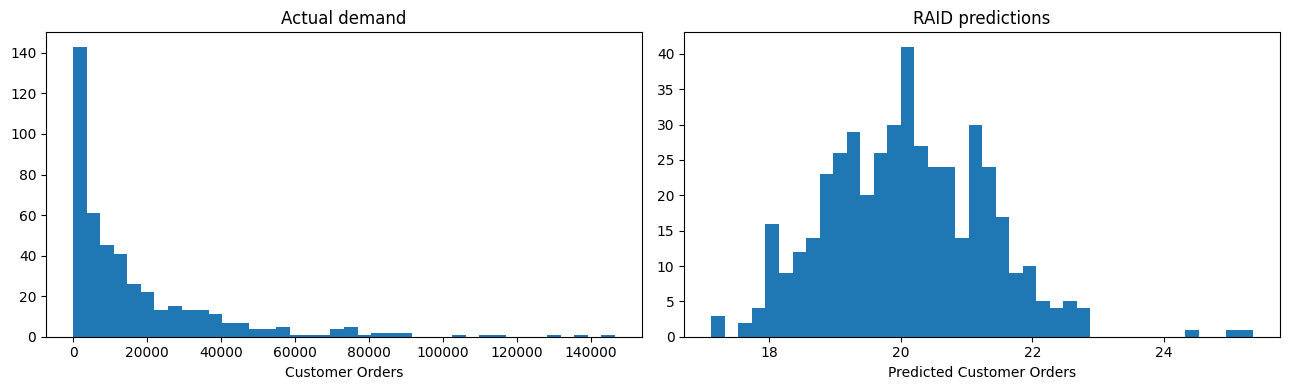

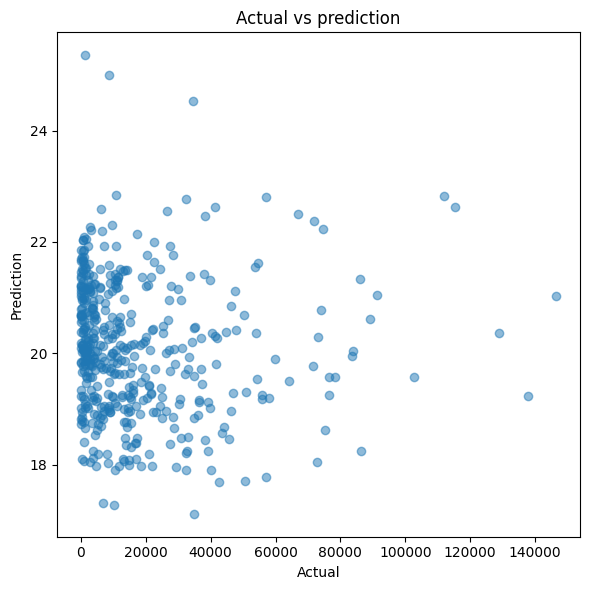

Pearson correlation: -0.040673327297921696
Mean prediction / mean actual: 0.0011672070733307032


In [4]:
print("Actual summary:")
display(predictions["actual"].describe(percentiles=[.01, .1, .5, .9, .99]).to_frame())
print("Prediction summary:")
display(predictions["prediction"].describe(percentiles=[.01, .1, .5, .9, .99]).to_frame())

print("Prediction NaNs:", predictions["prediction"].isna().sum())
print("Actual NaNs:", predictions["actual"].isna().sum())
print("Negative predictions:", (predictions["prediction"] < 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(predictions["actual"], bins=40)
axes[0].set_title("Actual demand")
axes[0].set_xlabel("Customer Orders")
axes[1].hist(predictions["prediction"], bins=40)
axes[1].set_title("RAID predictions")
axes[1].set_xlabel("Predicted Customer Orders")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(predictions["actual"], predictions["prediction"], alpha=.5)
ax.set_xlabel("Actual")
ax.set_ylabel("Prediction")
ax.set_title("Actual vs prediction")
plt.tight_layout()
plt.show()

print("Pearson correlation:", predictions[["actual", "prediction"]].corr().iloc[0, 1])
print("Mean prediction / mean actual:",
      predictions["prediction"].mean() / predictions["actual"].mean())

## 2. Load the exact saved RAID checkpoint

This recreates the architecture from the saved config and loads `raid_best.pt`. We are not retraining anything.

In [5]:
from src.models.raid import RAID

model = RAID(
    horizon=h,
    embedding_dim=int(m["embedding_dim"]),
    bottleneck_dim=int(m["bottleneck_dim"]),
    k=int(m["neighbors_k"]),
    gat_heads=int(m["gat_heads"]),
    gat_layers=int(m["gat_layers"]),
    dit_hidden=int(m["dit_hidden_dim"]),
    dit_layers=int(m["dit_layers"]),
    dit_heads=int(m["dit_heads"]),
    dit_dropout=float(m["dit_dropout"]),
    time_dim=int(m["time_embedding_dim"]),
    diffusion_steps=int(m["diffusion_train_steps"]),
    beta_start=float(m["beta_start"]),
    beta_end=float(m["beta_end"]),
    shape_clamp=float(m["shape_clamp"]),
    epsilon=float(m["epsilon"]),
    gate_bias_init=float(m["gate_bias_init"]),
    base_loss_weight=float(m["base_loss_weight"]),
    final_loss_weight=float(m["final_loss_weight"]),
).to(device)

checkpoint_path = ROOT / o["checkpoint_dir"] / "raid_best.pt"
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

emb_t = torch.as_tensor(embeddings, dtype=torch.float32, device=device)
print("Checkpoint:", checkpoint_path)
print("Best epoch:", checkpoint.get("best_epoch"))
print("Best recorded training loss:", checkpoint.get("best_loss"))
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Checkpoint loaded successfully.")

Checkpoint: /mnt/d/SEM 7/Honours by Research/GitHub_Sundial/ColdStart_Sundial/artifacts/Intel_SKU/checkpoints/raid_aggregate/raid_best.pt
Best epoch: 44
Best recorded training loss: 14847756.75
Model parameters: 337269
Checkpoint loaded successfully.


## 3. Pick one test SKU and rebuild its donor set exactly as evaluation does

Change `TARGET_SKU` if you want to inspect another SKU. Donors are training SKUs launched strictly before the target origin and with complete `h`-week history immediately before launch.

In [6]:
meta_by_sku = metadata.set_index("sku")
series = {
    str(sku): group.set_index("week")[d["target_column"]].sort_index()
    for sku, group in demand.groupby(d["sku_column"])
}
test_cases = cases[cases["target_sku"].astype(str).isin(test_skus)].copy()

TARGET_SKU = sorted(test_skus)[0]  # edit this after looking at the available cases
case = test_cases.loc[test_cases["target_sku"].astype(str) == TARGET_SKU].iloc[0]
target = str(case["target_sku"])
origin = int(case["origin_week"])
history_weeks = pd.RangeIndex(origin - h, origin)

donors = []
for sku in sorted(train_skus):
    if int(meta_by_sku.loc[sku, d["launch_column"]]) >= origin:
        continue
    history = series[sku].reindex(history_weeks)
    if history.notna().all():
        donors.append((sku, history.to_numpy(dtype=np.float32)))

if not donors:
    raise RuntimeError(f"No complete pre-origin donors for {target}, origin={origin}")

target_vec = embeddings[sku_to_idx[target]]
sims = np.array([embeddings[sku_to_idx[sku]] @ target_vec for sku, _ in donors])
order = np.argsort(-sims)[:min(int(m["neighbors_k"]), len(donors))]
donors = [donors[i] for i in order]
donor_skus = [sku for sku, _ in donors]
donor_hist_np = np.stack([hist for _, hist in donors]).astype(np.float32)
donor_idx = [sku_to_idx[sku] for sku in donor_skus]
donor_hist_t = torch.as_tensor(donor_hist_np, device=device)

actual = series[target].reindex(pd.RangeIndex(origin, origin + h)).to_numpy(dtype=float)

print("Target SKU:", target)
print("Launch/origin week:", origin)
print("Forecast weeks:", (origin, origin + h - 1))
print("Number of selected donors:", len(donors))
print("Target actual summary: min/mean/max =", np.min(actual), np.mean(actual), np.max(actual))
print("Donor history shape:", donor_hist_np.shape)
print("Donor raw demand summary: min/mean/max =",
      np.min(donor_hist_np), np.mean(donor_hist_np), np.max(donor_hist_np))
pd.DataFrame({
    "donor_sku": donor_skus,
    "metadata_similarity": sims[order],
    "history_mean": donor_hist_np.mean(axis=1),
    "history_std": donor_hist_np.std(axis=1),
    "history_min": donor_hist_np.min(axis=1),
    "history_max": donor_hist_np.max(axis=1),
}).head(20)

Target SKU: SKU-A-5
Launch/origin week: 158
Forecast weeks: (158, 170)
Number of selected donors: 14
Target actual summary: min/mean/max = 0.0 19371.46153846154 115334.0
Donor history shape: (14, 13)
Donor raw demand summary: min/mean/max = 0.0 61545.125 382596.0


,donor_sku,metadata_similarity,history_mean,history_std,history_min,history_max
0,SKU-A-4,0.909288,76156.460938,34358.523438,30175.0,140303.0
1,SKU-A-3,0.899495,330.769226,472.205658,0.0,1274.0
2,SKU-D-4,0.888995,31637.769531,6134.607910,19841.0,43233.0
3,SKU-F-4,0.846835,183498.390625,51963.101562,114267.0,295606.0
4,SKU-B-4,0.843194,63383.152344,26294.248047,8567.0,99650.0
5,SKU-C-4,0.842436,267337.218750,76277.148438,142770.0,382596.0
6,SKU-F-3,0.821623,4166.922852,2473.023926,1369.0,9315.0
7,SKU-N-4,0.820070,41650.847656,11226.387695,24602.0,63614.0
8,SKU-E-3,0.813254,673.615356,1049.196655,0.0,3822.0
9,SKU-V-4,0.809795,23219.923828,7015.522949,10287.0,31465.0


## 4. Inspect the base forecast before diffusion

Base forecast (before diffusion):
[18.457 20.139 20.536 21.73  18.548 19.449 19.328 19.982 23.012 21.554
 20.783 21.66  19.612]
Base min/mean/max: 18.456911 20.368448 23.012455
Learned scale_mean raw params [scale_raw, offset]: [[ 2.679255 20.36845 ]]
Positive scale after softplus: 2.745617628097534
Retrieval weights sum: 1.0000001
Top donor weights:


,donor_sku,weight,history_mean,history_std
0,SKU-A-4,0.076895,76156.460938,34358.523438
1,SKU-A-3,0.076143,330.769226,472.205658
2,SKU-D-4,0.075346,31637.769531,6134.607910
3,SKU-F-4,0.072225,183498.390625,51963.101562
4,SKU-B-4,0.071962,63383.152344,26294.248047
5,SKU-C-4,0.071907,267337.218750,76277.148438
6,SKU-F-3,0.070421,4166.922852,2473.023926
7,SKU-N-4,0.070311,41650.847656,11226.387695
8,SKU-E-3,0.069832,673.615356,1049.196655
9,SKU-V-4,0.069590,23219.923828,7015.522949


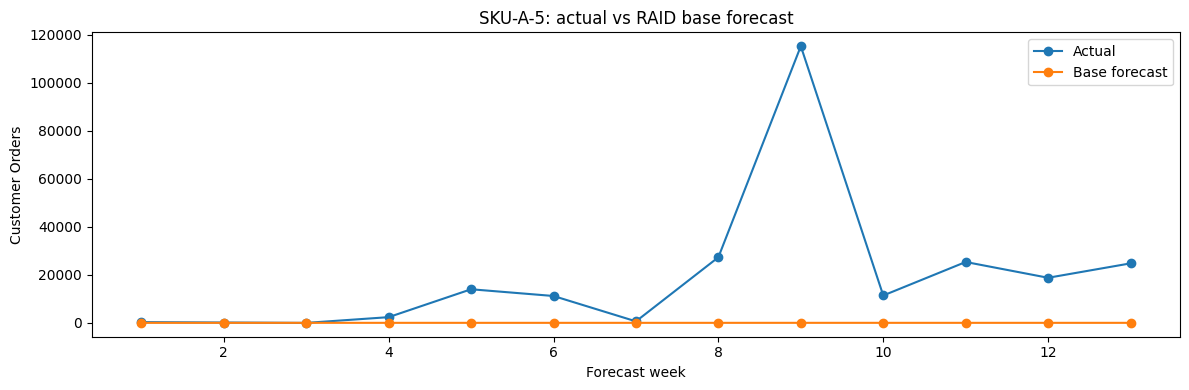

In [7]:
with torch.no_grad():
    raw, compact, graph_context, adjacency = model.graph(emb_t)
    ti = torch.tensor([sku_to_idx[target]], dtype=torch.long, device=device)
    di = torch.tensor(donor_idx, dtype=torch.long, device=device).unsqueeze(0)
    dh = donor_hist_t.unsqueeze(0)
    dm = torch.ones((1, len(donor_idx)), dtype=torch.bool, device=device)

    target_raw = raw[ti]
    target_compact = compact[ti]
    donor_raw = raw[di]
    base, weights = model.base_forecast(target_raw, target_compact, donor_raw, dh, dm)
    base_np = base.squeeze(0).cpu().numpy()
    weights_np = weights.squeeze(0).cpu().numpy()
    scale_mean_params = model.scale_mean(target_compact).cpu().numpy()

print("Base forecast (before diffusion):")
print(np.round(base_np, 3))
print("Base min/mean/max:", base_np.min(), base_np.mean(), base_np.max())
print("Learned scale_mean raw params [scale_raw, offset]:", scale_mean_params)
print("Positive scale after softplus:", float(torch.nn.functional.softplus(
    model.scale_mean(target_compact)[:, :1]
).item()))
print("Retrieval weights sum:", weights_np.sum())
print("Top donor weights:")
display(pd.DataFrame({
    "donor_sku": donor_skus,
    "weight": weights_np,
    "history_mean": donor_hist_np.mean(axis=1),
    "history_std": donor_hist_np.std(axis=1),
}).sort_values("weight", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(1, h + 1), actual, marker="o", label="Actual")
ax.plot(range(1, h + 1), base_np, marker="o", label="Base forecast")
ax.set_title(f"{target}: actual vs RAID base forecast")
ax.set_xlabel("Forecast week")
ax.set_ylabel("Customer Orders")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Inspect final predictions and the diffusion correction

`predict_samples` returns `base + sigmoid(gate) * generated_residual`. We can inspect the gate and compare the sample-mean final forecast to the base forecast.

Sample tensor shape: (20, 13)
Sample predictions: min/mean/max = 16.953033 20.037071 24.010145
Final mean forecast: min/mean/max = 18.200829 20.037071 22.847647
Diffusion correction: min/mean/max = -0.5161495 -0.33137628 0.02973175
Gate sigmoid: 0.9999955892562866


,step,actual,base,final_prediction,diffusion_correction
0,1,318.0,18.456911,18.200829,-0.256083
1,2,159.0,20.138517,19.622368,-0.516150
2,3,0.0,20.536058,20.565790,0.029732
3,4,2389.0,21.730368,21.225765,-0.504602
4,5,14012.0,18.548138,18.209164,-0.338974
5,6,11210.0,19.448997,19.081509,-0.367489
6,7,637.0,19.328049,18.965405,-0.362644
7,8,27356.0,19.982197,19.709871,-0.272326
8,9,115334.0,23.012455,22.847647,-0.164808
9,10,11417.0,21.553581,21.109074,-0.444508


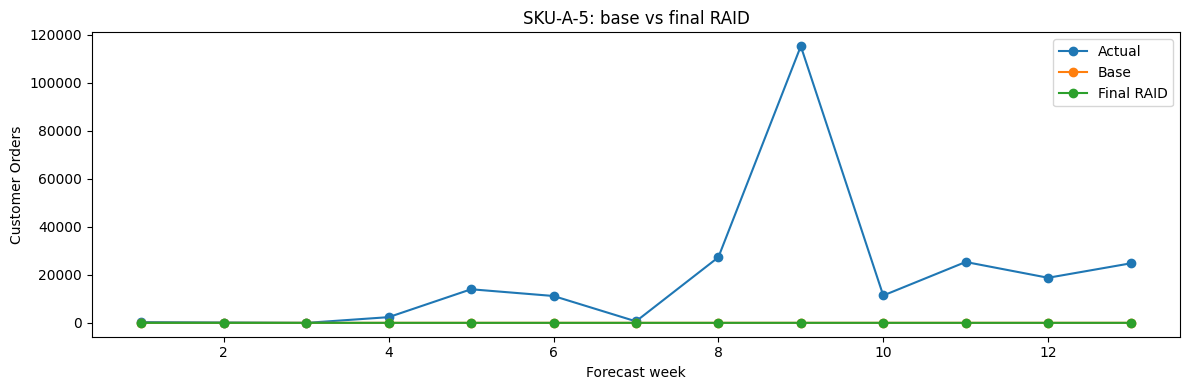

In [8]:
with torch.no_grad():
    samples = model.predict_samples(
        emb_t,
        sku_to_idx[target],
        donor_idx,
        donor_hist_t,
        num_samples=int(cfg["evaluation"]["num_samples"]),
        inference_steps=int(m["diffusion_inference_steps"]),
    ).cpu().numpy()

final_np = samples.mean(axis=0)
correction_np = final_np - base_np
gate_value = torch.sigmoid(model.gate(graph_context[ti])).item()

print("Sample tensor shape:", samples.shape)
print("Sample predictions: min/mean/max =", samples.min(), samples.mean(), samples.max())
print("Final mean forecast: min/mean/max =", final_np.min(), final_np.mean(), final_np.max())
print("Diffusion correction: min/mean/max =",
      correction_np.min(), correction_np.mean(), correction_np.max())
print("Gate sigmoid:", gate_value)

display(pd.DataFrame({
    "step": np.arange(1, h + 1),
    "actual": actual,
    "base": base_np,
    "final_prediction": final_np,
    "diffusion_correction": correction_np,
}))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(range(1, h + 1), actual, marker="o", label="Actual")
ax.plot(range(1, h + 1), base_np, marker="o", label="Base")
ax.plot(range(1, h + 1), final_np, marker="o", label="Final RAID")
ax.set_title(f"{target}: base vs final RAID")
ax.set_xlabel("Forecast week")
ax.set_ylabel("Customer Orders")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Check whether the training objective is dominated by raw-scale MSE

This runs a single forward pass with the target's held-out values only for diagnosis. Do not use these outputs to update weights or select the checkpoint. The target values are scoring labels, not valid inference inputs.

In [9]:
# Diagnostic-only loss calculation: no backward pass, no optimizer step.
y = torch.as_tensor(actual, dtype=torch.float32, device=device).unsqueeze(0)
ymask = torch.ones_like(y)

with torch.no_grad():
    diag = model(
        emb_t,
        ti,
        di,
        dh,
        dm,
        target_values=y,
        target_mask=ymask,
    )

for key in ["loss", "diffusion_loss", "base_loss", "final_loss"]:
    if key in diag:
        value = diag[key]
        print(f"{key}: {float(value.detach().cpu()):,.6g}")

print("Actual scale:", float(y.abs().mean().cpu()))
print("Base MSE:", float(((base - y) ** 2).mean().cpu()))
print("Final forecast MSE:", float(((torch.as_tensor(final_np, device=device).unsqueeze(0) - y) ** 2).mean().cpu()))

loss: 1.23934e+07
diffusion_loss: 1.99951
base_loss: 1.23934e+09
final_loss: 0.117257
Actual scale: 19371.462890625
Base MSE: 1239342080.0
Final forecast MSE: 1239352576.0


## 7. How to interpret the diagnostics

Use the outputs above to localize the failure:

- **Base forecast already near 20:** the problem is in `base_forecast`, especially how normalized donor shapes are reconstructed into original demand units.
- **Base is reasonable, final forecast collapses near 20:** the diffusion residual/sampling scale or gate is the likely problem.
- **Donor histories themselves are near 20:** the donor history construction or demand column may be wrong; check units and source columns.
- **Donor histories have realistic magnitudes but the base does not:** inspect the learned scale/offset head and whether donor mean/std are being used in reconstruction.
- **Training `base_loss` is enormous while final predictions remain small:** the loss scale and output reconstruction are inconsistent; don't fix this by multiplying predictions by an arbitrary constant.

Please share the printed values from Sections 3–6 (especially base summary, learned scale/offset, gate value, correction summary, and losses). We can then make a targeted correction instead of guessing.